2-column width: 180mm

1-column width: 88mm

All text should be sans-serif typeface, preferably Helvetica or Arial.

Maximum text size is 7pt. Minimum text size is 5pt.


In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import math

import util

from plot_setup import *


FOLDER = "/Users/brendan/Projects/trails/data/"
datafiles = [
    "scenarios|2026-06-27/data.json",
    "scenarios_wtw|2026-10-19/data.json",
    # just added this for (a).
    # "example-fig|2025-12-12/data.json",
]

In [2]:
dfs = [
    util.load_data(FOLDER + datafile) for datafile in datafiles
]
df = pd.concat(dfs)
util.describe(df)

ratios: [50.0 200.0 100.0 400.0 800.0]
patch recovery: [0.001]
max costs: [2.0 4.0 8.0]
boundary conditions: ['PERIODIC' 'SOLID' 'PERIODIC_Y']
num locations: [16]
random walker seeds: 2
random locations seeds: 1
patch recovery logic: ['LINEAR']
settings.searchStrategy : ['KANAI_SUZUKI']
settings.scenario : ['RANDOM_FIXED' 'RANDOM_DYNAMIC' 'CENTRAL_PLACE' 'WALL_TO_WALL']
settings.X : [100 200]
steps: 10000
Index(['averageTravelCost', 'averageTravelLength', 'totalImprovement',
       'thresholdImprovement', 'steps', 'paths', 'weightedHeadings',
       'avgHeading', 'avgSquareHeading', 'patches', 'locations', 'walkers',
       'settings.patchImprovement', 'settings.patchRecovery',
       'settings.maxCost', 'settings.boundaryConditions',
       'settings.numLocations', 'settings.randomSeedWalkers',
       'settings.randomSeedLocations', 'settings.recoveryLogic',
       'settings.improvementLogic', 'settings.searchStrategy',
       'settings.scenario', 'settings.X', 'ratio'],
      dtype='

In [7]:
def plot_scenarios(
    subfig,
    title="",
    snapshots=[400, 800, 1600, 3200, 6400],
    scenario="RANDOM_DYNAMIC",
    cost=4.0,
    ratio=400,
    random_seed=1,
    X=200,
    boundary="SOLID",
    letter=None,
):
    _df = df[
        (df["settings.scenario"] == scenario) &
        (df["settings.maxCost"] == cost) &
        (df["ratio"] == ratio) &
        (df["settings.randomSeedWalkers"] == random_seed) &
        (df["settings.X"] == X) &
        (df["settings.boundaryConditions"] == boundary)
    ]

    
    # fig
    axs = subfig.subplots(1, len(snapshots))

    
    # if letter:
    #     add_letter(axs[0], -0.33, 12/mm_to_inch, letter)
        
    # , figsize=(180/mm_to_inch, 36/mm_to_inch))
    # plt.subplots_adjust(wspace=0.5, hspace=0.2)
    for i, steps in enumerate(snapshots):
        row = _df[(_df["steps"] == steps)].iloc[0]
        
        
        axs[i].imshow(np.reshape(row["patches"], (X, X)), cmap=CMAP, vmin=0, vmax=1.0)
        axs[i].axis('off')
    subfig.suptitle(title, fontsize=FONTSIZE)





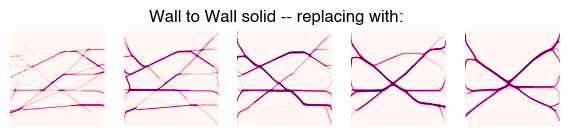

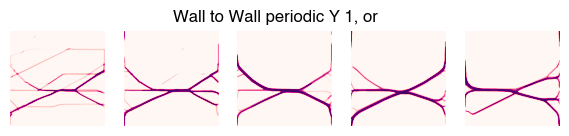

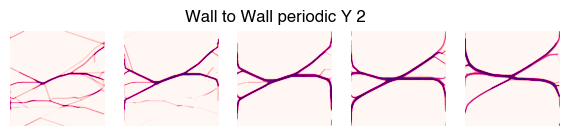

In [19]:
# Use to visualize just one.

fig = plt.figure(figsize=(two_column_width, 1 * (36/mm_to_inch)))
plot_scenarios(
    fig, random_seed=1, scenario="WALL_TO_WALL",
    boundary="SOLID", title="Wall to Wall solid -- replacing with:",
    cost=4.0,
    ratio=400,
)

fig = plt.figure(figsize=(two_column_width, 1 * (36/mm_to_inch)))
plot_scenarios(
    fig, random_seed=1, scenario="WALL_TO_WALL",
    boundary="PERIODIC_Y", title="Wall to Wall periodic Y 1, or",
    cost=4.0,
    ratio=400,
)

fig = plt.figure(figsize=(two_column_width, 1 * (36/mm_to_inch)))
plot_scenarios(
    fig, random_seed=2, scenario="WALL_TO_WALL",
    boundary="PERIODIC_Y", title="Wall to Wall periodic Y 2",
    cost=4.0,
    ratio=400,
)






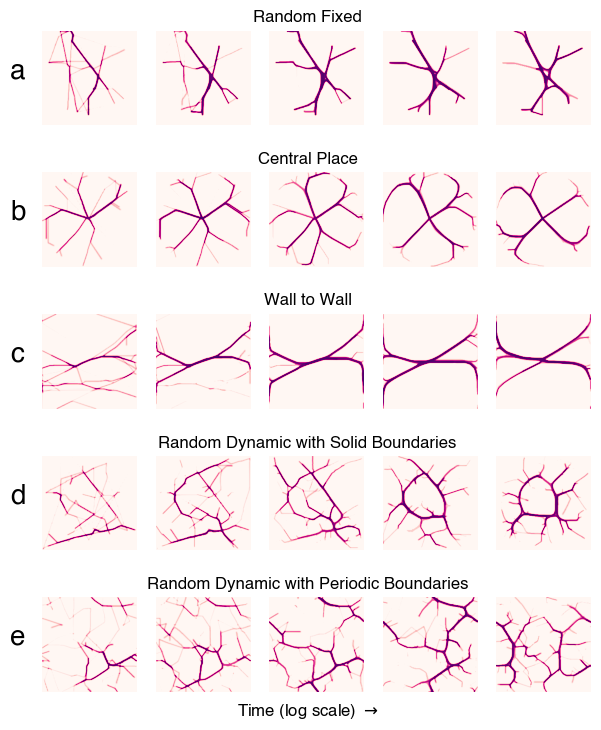

In [16]:
# Figure 3.

fig = plt.figure(figsize=(two_column_width, 5 * (36/mm_to_inch)))

all_figs = fig.subfigures(5, 1)

SNAPSHOTS = [400, 800, 1600, 3200, 6400]
X = 200


plot_scenarios(all_figs[0], random_seed=1, scenario="RANDOM_FIXED", title="Random Fixed")

plot_scenarios(all_figs[1], scenario="CENTRAL_PLACE", title="Central Place")

plot_scenarios(all_figs[2], scenario="WALL_TO_WALL",
               boundary="PERIODIC_Y", random_seed=2,
               title="Wall to Wall")

plot_scenarios(all_figs[3], scenario="RANDOM_DYNAMIC", title="Random Dynamic with Solid Boundaries")

plot_scenarios(all_figs[4], scenario="RANDOM_DYNAMIC", random_seed=2,
               boundary="PERIODIC", title="Random Dynamic with Periodic Boundaries")

for i, letter in enumerate(["a", "b", "c", "d", "e"]):
    add_letter(all_figs[i], 0.08, 0.5, letter)

# fig.supxlabel(r"Time (Log Scale) $\rightarrow$", fontsize=FONTSIZE)


plt.figtext(
    0.5,
    0.00,
    r"Time (log scale) $\rightarrow$",
    ha="center",
    fontsize=FONTSIZE,

    # style="italic",
);

fig.savefig("figures/3.pdf", bbox_inches="tight")
fig.savefig("figures/3.svg", bbox_inches="tight")
fig.savefig("figures/3.png", bbox_inches="tight", dpi=300)

In [9]:
def plot_nine(
    subfig,
    letter=None,
    steps=12800,
    scenario="RANDOM_DYNAMIC",
    random_seed=1,
    boundary="SOLID"):
    # fig, 
    axs = subfig.subplots(3, 3) #figsize=(80/mm_to_inch, 80/mm_to_inch))
    X = 200
    
    # if letter:
    #     add_letter(axs[0][0], -0.45, 18/mm_to_inch, letter)

    for r, ratio in enumerate([800, 400, 200]):
        for c, cost in enumerate([2.0, 4.0, 8.0]):
            # plot_scenarios(snapshots=[10000, 20000], X=200,
            #                ratio=ratio, cost=cost, boundary="SOLID", random_seed=1, scenario="RANDOM_DYNAMIC")
    
            print(ratio, cost, boundary)
            _df = df[
                (df["settings.scenario"] == scenario) &
                (df["settings.maxCost"] == cost) &
                (df["ratio"] == ratio) &
                (df["settings.randomSeedWalkers"] == random_seed) &
                (df["settings.X"] == X) &
                (df["settings.boundaryConditions"] == boundary)
            ]
            row = _df[(_df["steps"] == steps)].iloc[0]
    
            axs[r][c].imshow(np.reshape(row["patches"], (X, X)), cmap=CMAP, vmin=0, vmax=1)
            axs[r][c].axis('off')
    # return fig


800 2.0 SOLID
800 4.0 SOLID
800 8.0 SOLID
400 2.0 SOLID
400 4.0 SOLID
400 8.0 SOLID
200 2.0 SOLID
200 4.0 SOLID
200 8.0 SOLID
800 2.0 PERIODIC
800 4.0 PERIODIC
800 8.0 PERIODIC
400 2.0 PERIODIC
400 4.0 PERIODIC
400 8.0 PERIODIC
200 2.0 PERIODIC
200 4.0 PERIODIC
200 8.0 PERIODIC


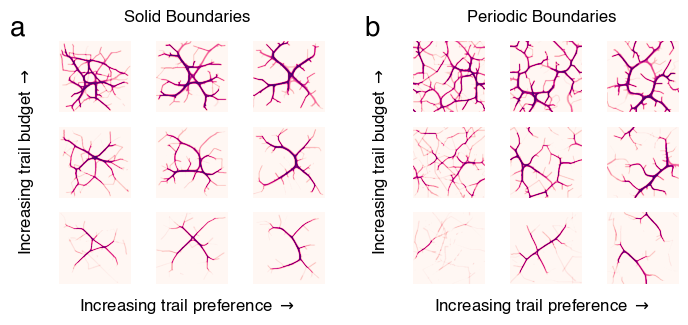

In [12]:
fig = fig = plt.figure(figsize=(two_column_width, 80/mm_to_inch))
left_fig, right_fig = fig.subfigures(1, 2)


STEPS = 10000
plot_nine(left_fig, random_seed=1, boundary="SOLID", steps=STEPS, letter="a")
left_fig.suptitle("Solid Boundaries", fontsize=FONTSIZE)
left_fig.supxlabel(r"Increasing trail preference $\rightarrow$", fontsize=FONTSIZE)
left_fig.supylabel(r"Increasing trail budget $\rightarrow$", fontsize=FONTSIZE)


plot_nine(right_fig, random_seed=2, boundary="PERIODIC", steps=STEPS, letter="b")
right_fig.suptitle("Periodic Boundaries", fontsize=FONTSIZE)
right_fig.supxlabel(r"Increasing trail preference $\rightarrow$", fontsize=FONTSIZE)
right_fig.supylabel(r"Increasing trail budget $\rightarrow$", fontsize=FONTSIZE)

add_letter(left_fig, 0, 0.9, "a")
add_letter(right_fig, 0, 0.9, "b")


fig.savefig("figures/4.pdf", dpi=DPI, bbox_inches="tight")
fig.savefig("figures/4.svg", dpi=DPI, bbox_inches="tight")
fig.savefig("figures/4.png", dpi=DPI, bbox_inches="tight")

In [58]:
# Potential improvement vs cost plot.
_df = df[
    (df["settings.scenario"] == "RANDOM_DYNAMIC") &
    # (df["settings.maxCost"] == cost) &
    # (df["ratio"] == ratio) &
    (df["steps"] == 10000) &
    # (df["settings.randomSeedWalkers"] == 2) &
    (df["settings.X"] == 100)
    # (df["settings.boundaryConditions"] == "SOLID")
]
# sns.relplot(_df, x="total

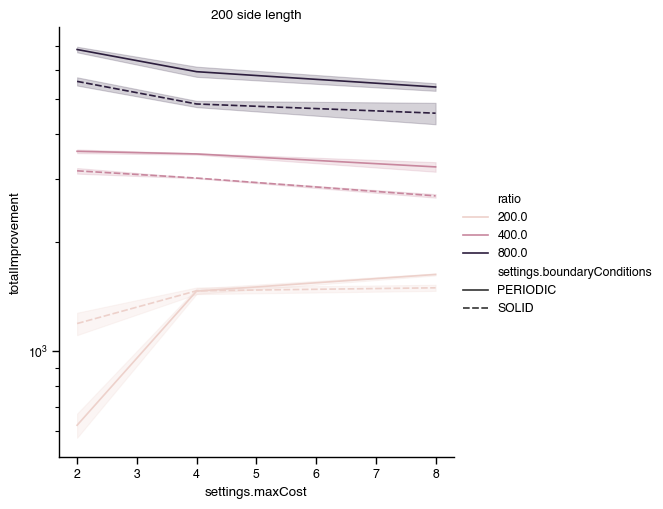

In [57]:
p = sns.relplot(data=_df, y="totalImprovement", hue="ratio", style="settings.boundaryConditions", x="settings.maxCost", kind="line")
p.set(yscale="log", title="200 side length")

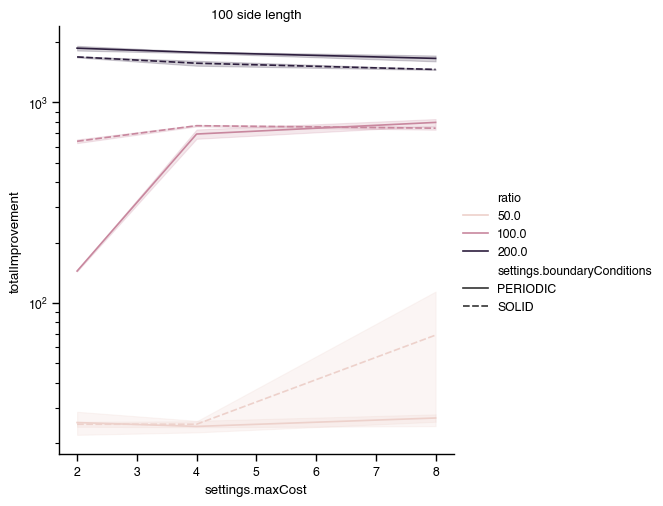

In [59]:
p = sns.relplot(data=_df, y="totalImprovement", hue="ratio", style="settings.boundaryConditions", x="settings.maxCost", kind="line")
p.set(yscale="log", title="100 side length")